Here we aim at finding the best way to define a neural network that can approximate any diffeomorphism 
$$  F : D \to D,
$$
where $D$ is the 2D disk.

Namely, we need not only injectivity of the neural network (that can be enforced by choosing an invertible structure), but also **surjectivity** of the network onto the image $D$. In other words, we need to find a proper way to enforce that $F(\partial D) = \partial D$. 

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np

torch.set_default_device(torch.device("mps" if torch.backends.mps.is_available() else "cpu"))
torch.set_default_dtype(torch.float32)
torch.manual_seed(0)

In [7]:
def plot_diffeo(F):
    fig = plt.figure(figsize = (10,10))
    ax = fig.add_subplot(1, 1, 1)
        
    ## First see what happens to concentric circles
    rs = torch.linspace(0,1, 10)
    thetas = torch.linspace(0, 2*torch.pi, 200)
    xs, ys = torch.cos(thetas), torch.sin(thetas)
    Xs = torch.stack([xs, ys], dim=-1).reshape(-1, 2)
    
    Fts = [F(r*Xs) for r in rs] # Array of F(circles)   
    for r in rs:
        Fr = F(r*Xs)
        xt, yt = Fr[:, 0].cpu().detach(), Fr[:, 1].cpu().detach()
        # plot circles dotted
        line, = ax.plot(r.cpu() * xs.cpu(), r.cpu() * ys.cpu(), linestyle='dotted')
        # plot F(circles) full
        ax.plot(xt, yt, color=line.get_color())


    ## Then what happens to two orthogonal straight lines
    ts = torch.linspace(0,1, 200)

    Fl0 = F(torch.stack([ts, torch.zeros_like(ts)], dim=-1).reshape(-1, 2)).cpu().detach()  # F(horizontal line)
    Fl1 = F(torch.stack([torch.zeros_like(ts),ts], dim=-1).reshape(-1, 2)).cpu().detach()   # F(vertical line)
    
    ax.plot(Fl0[:,0],Fl0[:,1])
    ax.plot(Fl1[:,0],Fl1[:,1])

        
    ax.grid(color=(0.9, 0.9, 0.9))
    ax.set_aspect("equal")
    ax.set_title("$F(x)$ for $x$ along concentric circles")
    plt.tight_layout()
    plt.show()

In [24]:
class AdditiveCoupling(nn.Module):
    def __init__(self, flip, hidden=32):
        super().__init__()
        self.flip = flip
        self.mlp = nn.Sequential(
            nn.Linear(1, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1), nn.Tanh()
        )
        nn.init.zeros_(self.mlp[-2].weight)
        nn.init.zeros_(self.mlp[-2].bias)

    def forward(self, z, inverse=False):
        a, b = (z[:, 1:], z[:, :1]) if self.flip else (z[:, :1], z[:, 1:])
        t = self.mlp(a)
        b = 2*b - t if inverse else (b + t)/2
        return torch.cat([b, a], 1) if self.flip else torch.cat([a, b], 1)

class InvertibleNN(nn.Module):
    def __init__(self, n_layers=8, hidden=32):
        super().__init__()
        self.layers = nn.ModuleList(
            [AdditiveCoupling(flip=i % 2 == 1, hidden=hidden) for i in range(n_layers)]
        )

    def forward(self, x, inverse=False):
        z = x
        for l in (reversed(self.layers) if inverse else self.layers):
            z = l(z, inverse)
        # d = (1 - (x[:, 0]**2 + x[:, 1]**2)**0.5).unsqueeze(-1)
        return z
        # return torch.stack([z[:, 0]*torch.cos(2*torch.pi*z[:, 1]), z[:, 0]*torch.sin(2*torch.pi*z[:, 1])], axis=-1)

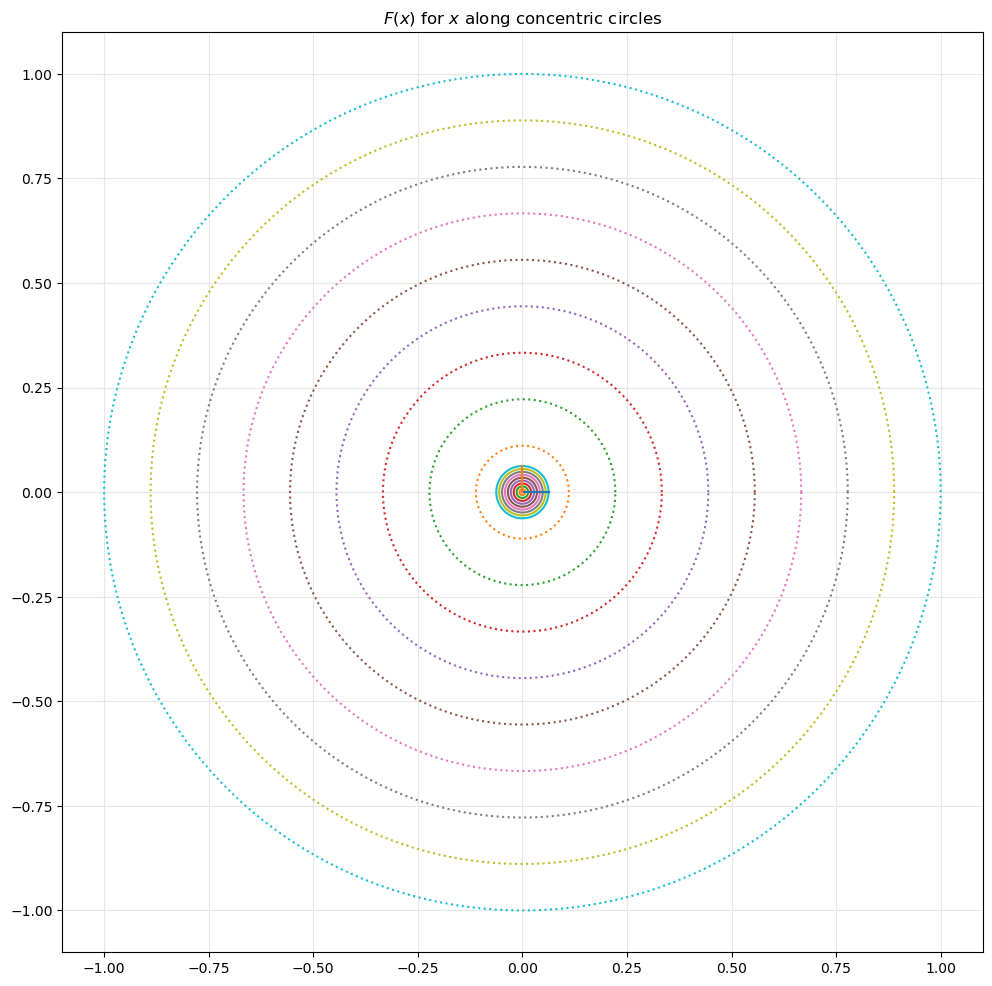

In [25]:
F = InvertibleNN()

plot_diffeo(F)

In [17]:
F(torch.stack([torch.tensor([0]), torch.tensor([.99])], dim=-1).reshape(-1, 2))

tensor([[0.0000, 0.0619]], grad_fn=<CatBackward0>)